El análisis de antigüedad de saldos en Cuentas por Cobrar (CxC) y Cuentas por Pagar (CxP) es una herramienta clave para evaluar la salud financiera y operativa de una organización. Permite identificar facturas vencidas, monitorear el riesgo de incumplimiento, optimizar la gestión del flujo de efectivo y fortalecer la toma de decisiones. A través de la clasificación de saldos por rangos de vencimiento, es posible detectar oportunidades de mejora en los procesos de cobranza y pago, contribuyendo a una administración financiera más eficiente y sostenible.

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
datos = pd.read_excel(r'data\Ar_.xls')

In [3]:
datos.head()

,Cust_Number,Invoice_Date,Due_Date,Ref_No,Trans_Type,Trans_Amount
0,795401,2000-08-20,2000-09-19,205605,CN,-474.70
1,795401,2000-10-15,2000-11-14,206300,IN,225.87
2,795401,2000-02-04,2000-03-06,207137,IN,180.92
3,516372,2000-02-17,2000-03-18,211206,IN,1610.87
4,516372,2000-04-30,2000-03-18,211206,TR,-1298.43


In [4]:
datos.dtypes

Cust_Number              int64
Invoice_Date    datetime64[us]
Due_Date        datetime64[us]
Ref_No                     str
Trans_Type                 str
Trans_Amount           float64
dtype: object

In [5]:
# consulta de la fecha mínima y máxima en los datos
datos['Invoice_Date'].min(), datos['Invoice_Date'].max()

(Timestamp('2000-02-04 00:00:00'), Timestamp('2000-12-10 00:00:00'))

In [7]:
# definir la fecha de corte como el 30 de octubre de 2000
corte = datetime(2000, 10, 30)

# calcular la antigüedad en días
datos['Antigüedad'] = (corte - pd.to_datetime(datos['Invoice_Date'])) / pd.Timedelta(days=1)

# crear una función para etiquetar la categoría de antigüedad
def etiquetar_antiguedad(row):
    if row['Antigüedad'] < 0:
        return 'Al corriente'
    elif row['Antigüedad'] <= 30:
        return '0-30 días'
    elif row['Antigüedad'] <= 60:
        return '31-60 días'
    elif row['Antigüedad'] <= 90:
        return '61-90 días'
    elif row['Antigüedad'] <= 120:
        return '91-120 días'
    else:
        return 'Más de 120 días'

# aplicar la función para etiquetar la categoría de antigüedad
datos['Categoría de Antigüedad'] = datos.apply(etiquetar_antiguedad, axis=1)

# contar cuántas operaciones caen dentro de cada categoría
conteo_operaciones = datos['Categoría de Antigüedad'].value_counts().reset_index()
conteo_operaciones.columns = ['Categoría de Antigüedad', 'Número de Operaciones']

# sumar el importe de las facturas en cada categoría
suma_importe = datos.groupby('Categoría de Antigüedad')['Trans_Amount'].sum().reset_index()
suma_importe.columns = ['Categoría de Antigüedad', 'Suma del Importe']

# combinar los dataframes utilizando un índice para asegurar todas las categorías
resultados = pd.merge(conteo_operaciones.set_index('Categoría de Antigüedad'), 
                      suma_importe.set_index('Categoría de Antigüedad'), left_index=True, right_index=True, how='outer').reset_index()

# reordenar el dataframe para que 'Al corriente' esté en el índice 0
resultados = resultados.reindex([resultados[resultados['Categoría de Antigüedad'] == 'Al corriente'].index[0]] + list(resultados.index.difference([resultados[resultados['Categoría de Antigüedad'] == 'Al corriente'].index[0]])))

# calcular el porcentaje relativo de 'Número de Operaciones'
resultados['% pct'] = ( (resultados['Número de Operaciones'] / resultados['Número de Operaciones'].sum()) * 100 ).round(2)

# reordenar las columnas del dataframe resultados
resultados = resultados[['Categoría de Antigüedad', 'Número de Operaciones', '% pct', 'Suma del Importe']]

# rellenar NaN con 0 en los resultados
resultados = resultados.fillna(0)

# formatear la columna 'Suma del Importe' con separadores de miles
resultados['Suma del Importe'] = resultados['Suma del Importe'].apply(lambda x: '{:,.0f}'.format(x))

# mostrar los resultados en un DataFrame
print("Resultados del Análisis de Antigüedad de Saldos:")
resultados

Resultados del Análisis de Antigüedad de Saldos:


,Categoría de Antigüedad,Número de Operaciones,% pct,Suma del Importe
4,Al corriente,452,58.55,"197,949"
0,0-30 días,189,24.48,"137,850"
1,31-60 días,107,13.86,"123,058"
2,61-90 días,15,1.94,"6,770"
3,91-120 días,2,0.26,549
5,Más de 120 días,7,0.91,"2,706"


In [8]:
# Convertir la columna 'Suma del Importe' de vuelta a valores numéricos
resultados['Suma del Importe'] = resultados['Suma del Importe'].str.replace(',', '').astype(float)

# Crear un gráfico de barras agrupadas
fig = px.bar(resultados, x='Categoría de Antigüedad', y='Suma del Importe', 
             title='Suma del Importe por Antigüedad', text='Suma del Importe')

fig.update_layout(barmode='group')
fig.update_traces(texttemplate='%{text:.2s}', textposition='outside')  # Mostrar valores en el gráfico

# Formatear el eje y con separadores de miles
fig.update_layout(yaxis_tickformat=',d')

fig.show()

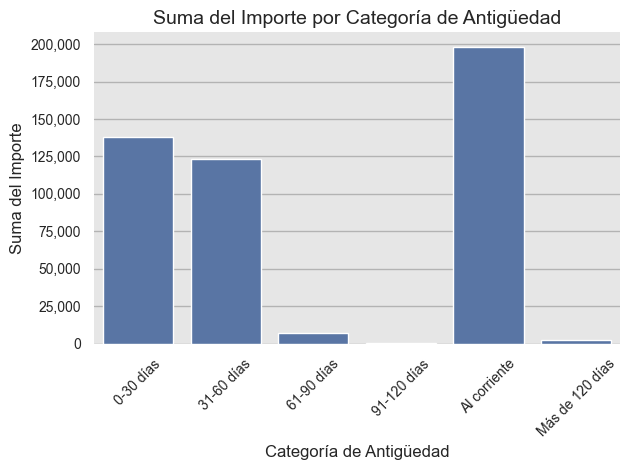

In [9]:

# Usando Seaborn
# Crear un DataFrame con los resultados
resultados = pd.merge(conteo_operaciones, suma_importe, on='Categoría de Antigüedad', how='outer').fillna(0)

# Calcular el porcentaje relativo de 'Número de Operaciones'
resultados['% pct'] = (resultados['Número de Operaciones'] / resultados['Número de Operaciones'].sum()) * 100

# Reordenar las columnas del DataFrame resultados
resultados = resultados[['Categoría de Antigüedad', 'Número de Operaciones', '% pct', 'Suma del Importe']]

# Configurar el estilo de Seaborn para que se parezca más a ggplot
sns.set(style="whitegrid", context="notebook", rc={"axes.facecolor": (0.9, 0.9, 0.9), "grid.color": "0.7", "font.size": 10})

# Crear el gráfico de barras con Seaborn
#plt.figure(figsize=(10, 6))
sns.barplot(data=resultados, x='Categoría de Antigüedad', y='Suma del Importe', color='b')
plt.title('Suma del Importe por Categoría de Antigüedad', fontsize=14)
plt.ylabel('Suma del Importe', fontsize=12)
plt.xlabel('Categoría de Antigüedad', fontsize=12)

# Rotar las etiquetas del eje x para una mejor legibilidad
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

# Formatear el eje y con separadores de miles
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Quitar los marcos de los ejes
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()


### Función final

In [10]:
def etiquetar_antiguedad(row):
    if row['Antigüedad'] < 0:
        return 'Al corriente'
    elif row['Antigüedad'] <= 30:
        return '0-30 días'
    elif row['Antigüedad'] <= 60:
        return '31-60 días'
    elif row['Antigüedad'] <= 90:
        return '61-90 días'
    elif row['Antigüedad'] <= 120:
        return '91-120 días'
    else:
        return 'Más de 120 días'

def antiguedad_saldos(datos, fecha_corte='2000-10-30'):
    # Convertir la fecha de corte a tipo datetime
    corte = datetime.strptime(fecha_corte, '%Y-%m-%d')
    
    # Calcular la antigüedad en días
    datos['Antigüedad'] = (corte - pd.to_datetime(datos['Invoice_Date'])) / pd.Timedelta(days=1)

    # Aplicar la función para etiquetar la categoría de antigüedad
    datos['Categoría de Antigüedad'] = datos.apply(etiquetar_antiguedad, axis=1)

    # Contar cuántas operaciones caen dentro de cada categoría
    conteo_operaciones = datos['Categoría de Antigüedad'].value_counts().reset_index()
    conteo_operaciones.columns = ['Categoría de Antigüedad', 'Número de Operaciones']

    # Sumar el importe de las facturas en cada categoría
    suma_importe = datos.groupby('Categoría de Antigüedad')['Trans_Amount'].sum().reset_index()
    suma_importe.columns = ['Categoría de Antigüedad', 'Suma del Importe']

    # Combinar los DataFrames utilizando un índice para asegurar todas las categorías
    resultados = pd.merge(conteo_operaciones.set_index('Categoría de Antigüedad'), 
                          suma_importe.set_index('Categoría de Antigüedad'), left_index=True, right_index=True, how='outer').reset_index()

    # Reordenar el DataFrame para que 'Al corriente' esté en el índice 0
    resultados = resultados.reindex([resultados[resultados['Categoría de Antigüedad'] == 'Al corriente'].index[0]] + list(resultados.index.difference([resultados[resultados['Categoría de Antigüedad'] == 'Al corriente'].index[0]])))

    # Calcular el porcentaje relativo de 'Número de Operaciones'
    resultados['% pct'] = ((resultados['Número de Operaciones'] / resultados['Número de Operaciones'].sum()) * 100).round(2)

    # Reordenar las columnas del DataFrame resultados
    resultados = resultados[['Categoría de Antigüedad', 'Número de Operaciones', '% pct', 'Suma del Importe']]

    # Rellenar NaN con 0 en los resultados
    resultados = resultados.fillna(0)

    # Formatear la columna 'Suma del Importe' con separadores de miles
    resultados['Suma del Importe'] = resultados['Suma del Importe'].apply(lambda x: '{:,.0f}'.format(x))

    print("Resultados del Análisis de Antigüedad de Saldos:")
    return resultados


In [11]:
# probar la función
antiguedad_saldos(datos, '2000-10-30' )

Resultados del Análisis de Antigüedad de Saldos:


,Categoría de Antigüedad,Número de Operaciones,% pct,Suma del Importe
4,Al corriente,452,58.55,"197,949"
0,0-30 días,189,24.48,"137,850"
1,31-60 días,107,13.86,"123,058"
2,61-90 días,15,1.94,"6,770"
3,91-120 días,2,0.26,549
5,Más de 120 días,7,0.91,"2,706"


### Conclusión

Comparando los datos resultantes son exactamanete iguales a los obtenidos con ACL, por supuesto que ACL tiene una ventaja al ser una API más amigable, pero el objetivo del código es demostrar que python puede realizar sin mucho esfuerzo la misma funcionalidad.